In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [29]:
#  Load Dataset
df = pd.read_csv("emails.csv")
df.head()


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [30]:
#preprocessing
df.drop('Email No.', axis=1, inplace=True)
df.dropna(subset=['Prediction'], inplace=True)

In [31]:
X = df.drop('Prediction', axis=1)
y = df['Prediction'].astype(int)

print("Spam / Not Spam Count:")
print(y.value_counts())

Spam / Not Spam Count:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [32]:
# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature Scaling
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [33]:
# KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

pred1 = knn.predict(X_test)

print("\nKNN CLASSIFICATION")
print("Accuracy:", accuracy_score(y_test, pred1))
print("Precision:", precision_score(y_test, pred1))
print("Recall:", recall_score(y_test, pred1))
print("F1 Score:", f1_score(y_test, pred1))
print("confusion matrix", confusion_matrix(y_test, pred1))



KNN CLASSIFICATION
Accuracy: 0.8454106280193237
Precision: 0.6588785046728972
Recall: 0.9527027027027027
F1 Score: 0.7790055248618785
confusion matrix [[593 146]
 [ 14 282]]



SVM CLASSIFICATION
Accuracy: 0.9468599033816425
Precision: 0.8950819672131147
Recall: 0.9222972972972973
F1 Score: 0.908485856905158


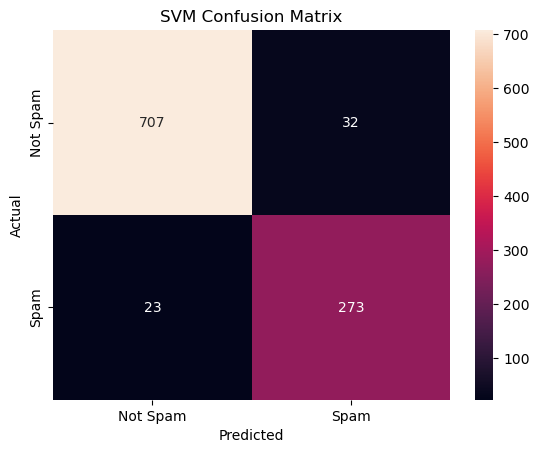

In [36]:
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

pred2 = svm.predict(X_test)

print("\nSVM CLASSIFICATION")
print("Accuracy:", accuracy_score(y_test, pred2))
print("Precision:", precision_score(y_test, pred2))
print("Recall:", recall_score(y_test, pred2))
print("F1 Score:", f1_score(y_test, pred2))

# SVM Confusion Matrix
cm2 = confusion_matrix(y_test, pred2)

sns.heatmap(cm2, annot=True, fmt='d',
            xticklabels=['Not Spam', 'Spam'],
            yticklabels=['Not Spam', 'Spam'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()